# Emoji-Intent-Aware 4-Class Classification for Bangla Sarcasm & Offensive Text Detection
## SarcOff Dataset -- Train/CV on `sarcoff-train_data.xlsx`, Hold-out Evaluation on `Test_Data.xlsx`

**Task:** single-label 4-way classification -- `pure_sarcastic`, `pure_offensive`, `sarcastic_offense`, `neutral` -- not binary multitask.

**Core contributions:**
1. Corpus-derived, leakage-free per-emoji **class propensity** features (m-estimate smoothed) as auxiliary signal for a 4-way softmax classifier.
2. Emoji-anchored, language-independent signal for code-mixed Bangla/Banglish/English text.
3. Domain- and class-stratified 5-fold CV, ensemble hold-out evaluation.
4. **Per-class emoji vs. word contribution** analysis (LIME on the held-out test set) and a dedicated **error analysis** section.

## Section 0 -- Environment, Dependencies & Global Configuration

In [7]:
# Kaggle/Colab: install once.
!pip install -q "transformers>=4.40" "datasets" "scikit-learn" "pandas" "numpy" \
                "openpyxl" "emoji>=2.10" "lime" "hyperopt" "scipy" \
                "matplotlib" "seaborn" "tqdm" "kagglehub"

In [8]:
import os, re, random, copy, warnings, math
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import emoji as emojilib
warnings.filterwarnings("ignore")

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

CLASS_NAMES = ["pure_sarcastic", "pure_offensive", "sarcastic_offense", "neutral"]
N_CLASSES = 4

CFG = {
    "MODEL_NAME": "xlm-roberta-base",
    "MAX_LEN": 128,
    "EPOCHS": 20,
    "PATIENCE": 3,
    "WEIGHT_DECAY": 1e-2,           # lr/batch_size/dropout/shared_dim/task_dim are HPO-selected (Section 12 -> BEST_HP)
    "INTENT_MIN_COUNT": 5,
    "INTENT_SMOOTH_M": 2.0,
    "N_SPLITS": 5,
    "WARMUP_RATIO": 0.1,
    "GRAD_CLIP": 1.0,
    "AUGMENT_P": 0.3,
    "HPO_N_TRIALS": 30,
    "HPO_PROXY_SIZE": 600,
    "HPO_PROXY_EPOCHS": 5,
    "LIME_SAMPLES": 500,
    "LIME_INFER_BATCH": 64,
    "LIME_AUTOCAST": True,
    "LIME_PER_CLASS_N": 40,          # samples explained per class in Section 14 (cost control)
    "BOOTSTRAP_N": 2000,
}
seed_everything()

Using device: cuda


## Section 1 -- Dataset Acquisition & Label Transformation

The dataset ships as two files: `sarcoff-train_data.xlsx` (3,000 rows, 4-class one-hot labels + `Domain`) and `Test_Data.xlsx` (500 rows, same 4-class scheme, no `Domain`). Each row is **exactly one-hot** across `pure_sarcastic`, `pure_offensive`, `sarcastic_offense`, `neutral` -- this is a **single-label 4-way classification task**, so the one-hot block is collapsed to one integer `class_id` and the model is trained with a single softmax head, not two binary heads. Both files are pulled via `kagglehub` so the notebook is self-contained on Kaggle.

In [9]:
import kagglehub
import os

# 1. Download the dataset
DATASET_PATH = kagglehub.dataset_download("mohammodhamedhasan/emo-sarcoff")
print(f"Dataset path: {DATASET_PATH}")

# 2. Helper function to search recursively
def _find_file(root, keyword):
    for dirpath, dirnames, filenames in os.walk(root):
        for fn in filenames:
            if keyword.lower() in fn.lower() and fn.lower().endswith((".xlsx", ".xls")):
                return os.path.join(dirpath, fn)
    raise FileNotFoundError(f"No file containing '{keyword}' found in {root}")

# 3. Find the files by searching the whole dataset path
TRAIN_FILE = _find_file(DATASET_PATH, "sarcoff-train")
TEST_FILE  = _find_file(DATASET_PATH, "Test_Data")

print(f"Train file: {TRAIN_FILE}")
print(f"Test  file: {TEST_FILE}")

Dataset path: /kaggle/input/datasets/mohammodhamedhasan/emo-sarcoff
Train file: /kaggle/input/datasets/mohammodhamedhasan/emo-sarcoff/Phase 2 /sarcoff-train data.xlsx
Test  file: /kaggle/input/datasets/mohammodhamedhasan/emo-sarcoff/Phase 2 /Test_Data.xlsx


In [10]:
CLASS_COLS_CANON = ["pure_sarcastic", "pure_offensive", "sarcastic_offense", "neutral"]  # index == class_id

def standardize_columns(frame):
    """Map either the train (lowercase) or test (Title Case) header variants to a
    single canonical schema: text, pure_sarcastic, pure_offensive, sarcastic_offense,
    neutral, [domain]."""
    rename = {}
    for c in frame.columns:
        key = c.strip().lower().replace(" ", "_")
        if key == "comment":
            rename[c] = "text"
        elif key == "domain":
            rename[c] = "domain"
        elif key in CLASS_COLS_CANON:
            rename[c] = key
    out = frame.rename(columns=rename)
    missing = [c for c in ["text"] + CLASS_COLS_CANON if c not in out.columns]
    if missing:
        raise ValueError(f"Missing expected columns after standardization: {missing}")
    return out

def transform_labels(frame):
    """4-way one-hot (mutually exclusive) -> single integer class_id (0..3), matching CLASS_COLS_CANON order."""
    onehot = frame[CLASS_COLS_CANON].to_numpy()
    row_sums = onehot.sum(axis=1)
    if not np.all(row_sums == 1):
        bad = int((row_sums != 1).sum())
        raise ValueError(f"{bad} rows are not exactly one-hot across {CLASS_COLS_CANON}")
    frame = frame.copy()
    frame["class_id"] = onehot.argmax(axis=1)
    return frame

df_train_raw = transform_labels(standardize_columns(pd.read_excel(TRAIN_FILE)))
df_test_raw  = transform_labels(standardize_columns(pd.read_excel(TEST_FILE)))

if "domain" not in df_train_raw.columns:
    raise ValueError("Train file is missing the 'Domain' column required for stratified CV.")
df_train_raw["domain"] = df_train_raw["domain"].astype(str)

print(f"Train raw: {df_train_raw.shape} | Test raw: {df_test_raw.shape}")
print(df_train_raw[["text", "class_id", "domain"]].head(3))

Train raw: (3000, 7) | Test raw: (500, 6)
                                                text  class_id  \
0  Tech Reviewer gulo taka kheye baje gadget ke b...         0   
1  Wah re religious teacher, shob jaygay hatred c...         2   
2  Ajker news niye comment ta ekdom baje, amar mo...         1   

                       domain  
0                  Technology  
1  Social, Culture & Personal  
2        International & News  


### Integrity checks & de-duplication (train only -- the test file is the fixed official hold-out and is never dropped/modified)

In [11]:
for name, frame in [("train", df_train_raw), ("test", df_test_raw)]:
    assert set(frame["class_id"].unique()) <= set(range(N_CLASSES)), f"{name}: bad class_id values"
    assert frame[["text", "class_id"]].isnull().sum().sum() == 0, f"{name}: has nulls"

print(f"Train raw: {len(df_train_raw)} | Test raw (fixed, untouched): {len(df_test_raw)}")

n_exact = df_train_raw.duplicated(subset=["text", "class_id"]).sum()
df_train = df_train_raw.drop_duplicates(subset=["text", "class_id"]).reset_index(drop=True)
print(f"Train exact dedup: {n_exact} removed -> {len(df_train)}")

n_near = df_train.duplicated(subset=["text"], keep="first").sum()
if n_near > 0:
    df_train = df_train.drop_duplicates(subset=["text"], keep="first").reset_index(drop=True)
    print(f"Train near-dedup (same text, diff label): {n_near} removed -> {len(df_train)}")

df_test = df_test_raw.reset_index(drop=True)  # kept as-is: official hold-out set

print(f"\nFinal TRAIN pool : {len(df_train)}")
print("Class counts (train):", df_train["class_id"].value_counts().sort_index().to_dict())
print(f"Final TEST hold-out: {len(df_test)}")
print("Class counts (test) :", df_test["class_id"].value_counts().sort_index().to_dict())

Train raw: 3000 | Test raw (fixed, untouched): 500
Train exact dedup: 452 removed -> 2548

Final TRAIN pool : 2548
Class counts (train): {0: 668, 1: 551, 2: 688, 3: 641}
Final TEST hold-out: 500
Class counts (test) : {0: 136, 1: 130, 2: 128, 3: 106}


## Section 2 -- Emoji Extraction & Corpus Analysis (library-based)\n\nUses the `emoji` library's `EMOJI_DATA` table, covering supplemental symbols, variation selectors, regional indicators and ZWJ sequences -- more complete than a hand-written regex.

In [12]:
from collections import Counter, defaultdict

def extract_emojis(text):
    """Return the list of emoji characters in text (library-backed, complete)."""
    return [c for c in str(text) if c in emojilib.EMOJI_DATA]

df_train["emojis"]      = df_train["text"].apply(extract_emojis)
df_train["emoji_count"] = df_train["emojis"].apply(len)

emoji_freq = Counter(e for lst in df_train["emojis"] for e in lst)
print(f"Train sentences with >=1 emoji : {(df_train.emoji_count>0).sum()} / {len(df_train)} "
      f"({(df_train.emoji_count>0).mean()*100:.1f}%)")
print(f"Mean emojis / sentence   : {df_train.emoji_count.mean():.2f}")
print(f"Distinct emojis in corpus: {len(emoji_freq)}")
print("\nTop-15 emojis:")
for e, n in emoji_freq.most_common(15):
    print(f"  {e}  {n:>4}  {emojilib.EMOJI_DATA[e]['en']}")

Train sentences with >=1 emoji : 1579 / 2548 (62.0%)
Mean emojis / sentence   : 0.93
Distinct emojis in corpus: 163

Top-15 emojis:
  🤣   277  :rolling_on_the_floor_laughing:
  😂   237  :face_with_tears_of_joy:
  🤮   115  :face_vomiting:
  🤡    78  :clown_face:
  😏    71  :smirking_face:
  💩    71  :pile_of_poo:
  😁    60  :beaming_face_with_smiling_eyes:
  👎    58  :thumbs_down:
  😡    57  :enraged_face:
  🤬    51  :face_with_symbols_on_mouth:
  ♂    40  :male_sign:
  👏    40  :clapping_hands:
  ❤    40  :red_heart:
  🙄    40  :face_with_rolling_eyes:
  🎉    37  :party_popper:


## Section 3 -- Emoji to Bangla Phrase Expansion (full corpus coverage)

Emojis are converted to Bangla phrases to surface hidden emotional/pragmatic intent for the encoder. A curated dictionary covers the highest-frequency, intent-bearing emojis with sarcasm/offense-aware wording; every remaining emoji falls back to a **distinct** `[ইমোজি: <name>]` token derived from the `emoji` library's short name -- so no two emojis ever collapse into one generic symbol, giving 100% coverage with full semantic distinction.

In [13]:
CURATED_BANGLA = {
    "\U0001F923":"[ব্যঙ্গাত্মক হাসি]", "\U0001F602":"[কান্নাময় হাসি]", "\U0001F606":"[উচ্চস্বরে হাসি]",
    "\U0001F601":"[উজ্জ্বল হাসি]", "\U0001F603":"[প্রশস্ত হাসি]", "\U0001F642":"[মৃদু হাসি]", "\U0001F60A":"[সন্তুষ্ট হাসি]",
    "\U0001F60F":"[বাঁকা হাসি]", "\U0001F60E":"[আত্মবিশ্বাসী]", "\U0001F609":"[চোখ টিপ]", "\U0001F921":"[সং]",
    "\U0001F438":"[ব্যঙ্গ প্রতীক]", "\U0001F643":"[উল্টো হাসি]",
    "\U0001F621":"[রাগান্বিত]", "\U0001F620":"[ক্ষুব্ধ]", "\U0001F92C":"[গালিগালাজ]", "\U0001F624":"[ক্রুদ্ধ শ্বাস]",
    "\U0001F612":"[অসন্তুষ্ট]", "\U0001F611":"[বিরক্ত]", "\U0001F610":"[নির্বিকার]", "\U0001F644":"[চোখ ঘোরানো]",
    "\U0001F92E":"[বিতৃষ্ণা]", "\U0001F922":"[বমি ভাব]", "\U0001F480":"[মৃত্যু প্রতীক]", "\U0001F44E":"[অপছন্দ]",
    "\U0001F595":"[অশ্লীল অঙ্গভঙ্গি]", "\U0001F4A9":"[অবজ্ঞা প্রতীক]",
    "\U0001F62D":"[কাঁদছি]", "\U0001F622":"[দুঃখী]", "\U0001F614":"[বিষণ্ণ]", "\U0001F61E":"[হতাশ]", "\U0001F61F":"[উদ্বিগ্ন]",
    "\U0001F62B":"[ক্লান্ত]", "\U0001F629":"[বিরক্ত ক্লান্ত]", "\U0001F623":"[কষ্ট]", "\U0001F613":"[ঘর্মাক্ত]",
    "\U0001F62A":"[ঘুমঘুম]", "\U0001F634":"[ঘুমন্ত]", "\U0001F972":"[অশ্রুসিক্ত হাসি]", "\U0001F494":"[ভাঙা হৃদয়]",
    "\U0001F60D":"[মুগ্ধ]", "\U0001F970":"[ভালোবাসাময়]", "\U0001F618":"[চুম্বন]", "\u2764":"[ভালোবাসা]",
    "\U0001F9E1":"[কমলা হৃদয়]", "\U0001F49B":"[হলুদ হৃদয়]", "\U0001F499":"[নীল হৃদয়]", "\U0001F49A":"[সবুজ হৃদয়]",
    "\U0001F4AF":"[একশো ভাগ]", "\U0001F525":"[আগুন]", "\U0001F44F":"[তালি]", "\U0001F44D":"[পছন্দ]", "\U0001F64F":"[প্রার্থনা]",
    "\U0001F633":"[লজ্জিত]", "\U0001F62E":"[বিস্মিত]", "\U0001F62F":"[অবাক]", "\U0001F635":"[হতবিহ্বল]", "\U0001F974":"[বিভ্রান্ত]",
    "\U0001F914":"[ভাবছি]", "\U0001F926":"[হতাশ ভঙ্গি]", "\U0001F937":"[কাঁধ ঝাঁকানো]", "\U0001F636":"[নিরুত্তর]",
    "\U0001F440":"[নজর]", "\U0001F3AD":"[নাটকীয়তা]",
}

def expand_emojis(text):
    """Replace every emoji with a Bangla phrase; tail emojis get a DISTINCT named token."""
    out = []
    for ch in str(text):
        if ch in CURATED_BANGLA:
            out.append(f" {CURATED_BANGLA[ch]} ")
        elif ch in emojilib.EMOJI_DATA:
            name = emojilib.EMOJI_DATA[ch]["en"].strip(":").replace("_", " ")
            out.append(f" [ইমোজি: {name}] ")
        else:
            out.append(ch)
    return re.sub(r"\s+", " ", "".join(out)).strip()

def clean_text(text):
    text = re.sub(r"http\S+|www\.\S+", "", str(text))
    text = re.sub(r"[@#]\w+", "", text)
    return re.sub(r"\s+", " ", text).strip()

def preprocess(text):                        # raw -> model-input (expanded) text
    return expand_emojis(clean_text(text))

def preprocess_noemoji(text):
    """Preprocess without emoji expansion (ablation)."""
    return clean_text(text)

covered = sum(emoji_freq[e] for e in CURATED_BANGLA if e in emoji_freq)
total_occ = sum(emoji_freq.values())
if total_occ:
    print(f"Curated map: {len(CURATED_BANGLA)} emojis -> covers {covered}/{total_occ} = {covered/total_occ*100:.1f}% of occurrences")
for s in df_train["text"].iloc[[1, 2]]:
    print(f"\n  raw     : {s}\n  expanded: {preprocess(s)}")

Curated map: 64 emojis -> covers 1490/2376 = 62.7% of occurrences

  raw     : Wah re religious teacher, shob jaygay hatred chharray.
  expanded: Wah re religious teacher, shob jaygay hatred chharray.

  raw     : Ajker news niye comment ta ekdom baje, amar mote valo hoy nai. 🚫
  expanded: Ajker news niye comment ta ekdom baje, amar mote valo hoy nai. [ইমোজি: prohibited]


## Section 4 -- Leakage-Free Emoji Intent Encoder (core novelty)

Each emoji gets a **per-class propensity** vector estimated from the corpus -- P(class=c | emoji) for each of the 4 classes -- generalizing the old binary sarcasm/offensive propensities to the 4-way task. The `fit`/`transform` contract enforces leakage safety: `fit(texts, class_ids)` is called **only on a training split** (each CV fold's train rows, or the full train pool for the final ensemble); low-frequency emojis are smoothed toward the training class base-rates via an m-estimate `(hits_c + m*base_c)/(n + m)`. `transform(texts)` applies frozen training statistics to any split. The resulting **4 + 6 = 10-d** vector -- `[prop_0..prop_3 (per-class max over the sentence's emojis), dominant_class_prop, count, class_anchor_count, first_pos, last_pos, density]` -- is fed to the model in full.

In [14]:
class EmojiIntentEncoder:
    """Corpus-derived, leakage-free per-emoji, per-class propensity features (4-way)."""
    def __init__(self, min_count=None, m=None, anchor_thresh=0.40):
        self.min_count = CFG["INTENT_MIN_COUNT"] if min_count is None else min_count
        self.m         = CFG["INTENT_SMOOTH_M"]  if m is None else m
        self.anchor_thresh = anchor_thresh
        self.class_prop = {}                 # emoji -> np.array[N_CLASSES]
        self.base_prop  = np.full(N_CLASSES, 1.0 / N_CLASSES)
        self.dim = N_CLASSES + 6

    def fit(self, texts, class_ids):
        class_ids = np.asarray(class_ids)
        counts = np.bincount(class_ids, minlength=N_CLASSES).astype(float)
        self.base_prop = counts / max(counts.sum(), 1.0)
        stat = defaultdict(lambda: np.zeros(N_CLASSES))
        n_seen = defaultdict(int)
        for t, c in zip(texts, class_ids):
            for e in extract_emojis(t):
                stat[e][c] += 1; n_seen[e] += 1
        for e, vec in stat.items():
            n = n_seen[e]
            if n >= self.min_count:
                self.class_prop[e] = (vec + self.m * self.base_prop) / (n + self.m)
        return self

    def _vec(self, text):
        ems = extract_emojis(text); t = str(text); n = len(t)
        if not ems:
            out = list(self.base_prop) + [self.base_prop.max(), 0.0, 0.0, 0.5, 0.5, 0.0]
            return out
        props = np.stack([self.class_prop.get(e, self.base_prop) for e in ems])  # [n_emoji, N_CLASSES]
        per_class_max = props.max(axis=0)                 # strongest signal per class across sentence emojis
        dominant_prop = props.max(axis=1).mean()           # avg confidence of each emoji's own top class
        anchors = float((props.max(axis=1) >= self.anchor_thresh).sum())
        return list(per_class_max) + [dominant_prop, float(len(ems)), anchors,
                t.find(ems[0]) / max(n, 1), t.rfind(ems[-1]) / max(n, 1),
                len(ems) / max(len(t.split()), 1)]

    def transform(self, texts):
        return np.asarray([self._vec(t) for t in texts], dtype=np.float32)

_demo = EmojiIntentEncoder().fit(df_train.text.values, df_train.class_id.values)
print("Encoder demo -- distinct emojis with learned class propensities:", len(_demo.class_prop))
print("Base class rates:", np.round(_demo.base_prop, 3))
print("Example vector dim:", _demo.transform([df_train.text.iloc[1]]).shape, "(expected:", N_CLASSES + 6, ")")

Encoder demo -- distinct emojis with learned class propensities: 70
Base class rates: [0.262 0.216 0.27  0.252]
Example vector dim: (1, 10) (expected: 10 )


## Section 5 -- Domain + Class Stratification Key

Cross-validation folds are stratified on a **combined key** of `Domain` and `class_id`, so every fold preserves both the 4-way class balance (750 each) and the domain balance (500 each). The official 500-row test set has no `Domain` column and is used purely as the final hold-out -- it never participates in fold splitting or fitting.

In [15]:
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit

strat_key_train = df_train["domain"] + "_" + df_train["class_id"].astype(str)

print("Domain x class-id stratification cells (train):")
print(strat_key_train.value_counts().sort_index())
print(f"\nUnique strata: {strat_key_train.nunique()} | min count per stratum: {strat_key_train.value_counts().min()}")
print("\nClass distribution check:", df_train["class_id"].value_counts().sort_index().to_dict())

Domain x class-id stratification cells (train):
Education & Career_0            115
Education & Career_1             91
Education & Career_2            121
Education & Career_3            109
Entertainment & Lifestyle_0     105
Entertainment & Lifestyle_1      99
Entertainment & Lifestyle_2     125
Entertainment & Lifestyle_3     109
International & News_0          110
International & News_1           93
International & News_2           92
International & News_3           95
Social, Culture & Personal_0    113
Social, Culture & Personal_1     91
Social, Culture & Personal_2    123
Social, Culture & Personal_3    108
Sports & Recreation_0           125
Sports & Recreation_1            98
Sports & Recreation_2           120
Sports & Recreation_3           121
Technology_0                    100
Technology_1                     79
Technology_2                    107
Technology_3                     99
Name: count, dtype: int64

Unique strata: 24 | min count per stratum: 79

Class distribu

## Section 6 -- Emoji-Cluster Data Augmentation (train-only, seeded)\n\nSwaps an emoji for a semantically similar one within the same intent cluster. Clusters cover the corpus's most frequent emojis so the swap actually fires; the RNG is re-seeded per fold for reproducibility, and augmentation is applied to training folds only.

In [16]:
SARC_CLUSTER = ["\U0001F923","\U0001F602","\U0001F606","\U0001F601","\U0001F60F","\U0001F438","\U0001F921","\U0001F643","\U0001F60E"]
OFF_CLUSTER  = ["\U0001F621","\U0001F620","\U0001F92C","\U0001F624","\U0001F612","\U0001F644","\U0001F92E","\U0001F922","\U0001F480"]
SAD_CLUSTER  = ["\U0001F62D","\U0001F622","\U0001F614","\U0001F61E","\U0001F61F","\U0001F62B","\U0001F629","\U0001F623","\U0001F613","\U0001F494"]
POS_CLUSTER  = ["\U0001F60D","\U0001F970","\U0001F618","\u2764","\U0001F9E1","\U0001F49B","\U0001F499","\U0001F49A","\U0001F44D","\U0001F44F"]
CLUSTERS = [SARC_CLUSTER, OFF_CLUSTER, SAD_CLUSTER, POS_CLUSTER]
EMOJI_TO_CLUSTER = {e: c for c in CLUSTERS for e in c}

def augment_emoji_substitution(text, p=0.3, rng=random):
    """With prob p, swap ONE in-cluster emoji for a sibling. Operates on RAW text."""
    if rng.random() > p:
        return text
    chars = list(str(text))
    swap_positions = [i for i, ch in enumerate(chars) if ch in EMOJI_TO_CLUSTER]
    if not swap_positions:
        return text
    i = rng.choice(swap_positions)
    opts = [e for e in EMOJI_TO_CLUSTER[chars[i]] if e != chars[i]]
    if opts:
        chars[i] = rng.choice(opts)
    return "".join(chars)

_rng = random.Random(SEED)
_ex_candidates = [t for t in df_train.text.iloc[:50] if extract_emojis(t)]
if _ex_candidates:
    print("orig :", _ex_candidates[0])
    print("aug  :", augment_emoji_substitution(_ex_candidates[0], p=1.0, rng=_rng))
print(f"\nEmojis covered by clusters: {len(EMOJI_TO_CLUSTER)} "
      f"(accounts for {sum(emoji_freq.get(e,0) for e in EMOJI_TO_CLUSTER)} occurrences)")

orig : Tech Reviewer gulo taka kheye baje gadget ke bhalo bole. 😂
aug  : Tech Reviewer gulo taka kheye baje gadget ke bhalo bole. 🐸

Emojis covered by clusters: 38 (accounts for 1225 occurrences)


## Section 7 -- `EmoClassifier4` Model Architecture

```
   raw text --preprocess--> emoji-expanded text --> XLM-RoBERTa --> [CLS] (768)
        |                                                              |
        +--> EmojiIntentEncoder (leakage-free) --> intent vec (10) --> EmoIntentMLP (32)
                                                                       |
                              concat(768+32) --> shared dense (LayerNorm) --> fused
                                                                       |
                                              task_proj (LayerNorm, ReLU)
                                                                       |
                                              Linear(task_dim, 4)  -- single softmax head
                                                                       |
                                    [p_pure_sarcastic, p_pure_offensive, p_sarcastic_offense, p_neutral]
```

The two binary heads and the Cross-Stitch sharing unit from the earlier multitask design are removed -- there is only **one** task now (4-way classification), so there is nothing to cross-stitch between. `encode_fused()` still exposes the shared representation for downstream analysis (LIME, error inspection).

In [17]:
from transformers import AutoTokenizer, AutoModel, logging as hf_logging
hf_logging.set_verbosity_error()

tokenizer = AutoTokenizer.from_pretrained(CFG["MODEL_NAME"])

class EmoIntentMLP(nn.Module):
    """Encodes the (N_CLASSES+6)-d emoji intent vector into a dense representation."""
    def __init__(self, input_dim, hidden_dim=64, output_dim=32, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim), nn.ReLU())
    def forward(self, x): return self.net(x)

class EmoClassifier4(nn.Module):
    """Single-label 4-class classifier: XLM-RoBERTa [CLS] + emoji-intent features -> softmax(4)."""
    def __init__(self, xlmr=CFG["MODEL_NAME"], emo_dim=None, shared_dim=256, task_dim=128,
                 dropout=0.3, n_classes=N_CLASSES):
        super().__init__()
        emo_dim = (N_CLASSES + 6) if emo_dim is None else emo_dim
        self.encoder = AutoModel.from_pretrained(xlmr)
        h = self.encoder.config.hidden_size
        self.emo_mlp = EmoIntentMLP(emo_dim, 64, 32, dropout=0.2)
        self.shared = nn.Sequential(
            nn.Linear(h + 32, shared_dim), nn.LayerNorm(shared_dim), nn.ReLU(), nn.Dropout(dropout))
        self.task_proj = nn.Sequential(
            nn.Linear(shared_dim, task_dim), nn.LayerNorm(task_dim), nn.ReLU(), nn.Dropout(dropout))
        self.cls_head = nn.Linear(task_dim, n_classes)

    def encode_fused(self, input_ids, attention_mask, emoji_features):
        cls = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0, :]
        emo = self.emo_mlp(emoji_features)
        return self.shared(torch.cat([cls, emo], dim=1))

    def forward(self, input_ids, attention_mask, emoji_features, return_fused=False):
        fused = self.encode_fused(input_ids, attention_mask, emoji_features)
        h = self.task_proj(fused)
        logits = self.cls_head(h)                       # [B, N_CLASSES]
        return (logits, fused) if return_fused else logits

print(f"EmoClassifier4 defined. Output: {N_CLASSES}-way softmax over {CLASS_NAMES}")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

EmoClassifier4 defined. Output: 4-way softmax over ['pure_sarcastic', 'pure_offensive', 'sarcastic_offense', 'neutral']


## Section 8 -- PyTorch `Dataset` (tokenises emoji-expanded text + carries intent vector + integer class label)

In [18]:
from torch.utils.data import Dataset, DataLoader

class SarcOffDataset(Dataset):
    """Holds RAW texts (for traceability) + pre-expanded texts + intent features + class_id."""
    def __init__(self, raw_texts, intent_feats, class_ids, tok, max_len=None, pre_expanded=None):
        self.raw = list(raw_texts)
        self.max_len = CFG["MAX_LEN"] if max_len is None else max_len
        self.exp = [preprocess(t) for t in raw_texts] if pre_expanded is None else list(pre_expanded)
        self.emoji_features = torch.tensor(np.asarray(intent_feats), dtype=torch.float32)
        self.labels = torch.tensor(np.asarray(class_ids), dtype=torch.long)
        self.tok = tok
    def __len__(self): return len(self.raw)
    def __getitem__(self, i):
        enc = self.tok(self.exp[i], max_length=self.max_len, padding="max_length",
                       truncation=True, return_tensors="pt")
        return {"input_ids": enc["input_ids"].squeeze(0),
                "attention_mask": enc["attention_mask"].squeeze(0),
                "emoji_features": self.emoji_features[i],
                "label": self.labels[i]}

print("Dataset class ready.")

Dataset class ready.


## Section 9 -- Loss: Class-Weighted Cross-Entropy\n\nWith a single 4-way softmax head, the multitask uncertainty-weighting and per-task `pos_weight` are no longer applicable. Class imbalance (which can arise inside a fold even though the full corpus is balanced) is handled with per-class weights in `CrossEntropyLoss`, computed from the **fold's training labels only**.

In [19]:
def make_class_weights(labels, n_classes, device):
    """weight_c = N / (n_classes * count_c), guarded against zero-count classes."""
    labels = np.asarray(labels)
    counts = np.bincount(labels, minlength=n_classes).astype(float)
    counts = np.where(counts == 0, 1.0, counts)   # guard: avoid div-by-zero if a class is fold-absent
    weights = len(labels) / (n_classes * counts)
    return torch.tensor(weights, dtype=torch.float32, device=device)

print("Class-weighted CrossEntropyLoss helper ready.")

Class-weighted CrossEntropyLoss helper ready.


## Section 10 -- Threshold-Free Metrics & Bootstrap Helper Functions\n\nWith a single softmax head, class assignment is `argmax(softmax(logits))` -- there is no per-class decision threshold to calibrate (unlike the old sigmoid-per-task setup). `bootstrap_ci` is retained for confidence intervals on multi-class metrics.

In [20]:
from scipy.stats import ttest_rel, wilcoxon

def bootstrap_ci(y_true, y_pred_or_prob, metric_fn, B=None, alpha=0.05):
    """Bootstrap (1-alpha) CI for any (y_true, y_pred/prob) -> scalar metric function."""
    B = CFG["BOOTSTRAP_N"] if B is None else B
    rng = np.random.default_rng(SEED)
    n = len(y_true)
    scores = np.empty(B)
    for i in range(B):
        idx = rng.choice(n, n, replace=True)
        scores[i] = metric_fn(y_true[idx], y_pred_or_prob[idx])
    lo, hi = np.percentile(scores, [alpha/2*100, (1-alpha/2)*100])
    return float(scores.mean()), float(lo), float(hi)

print("Bootstrap helper ready.")

Bootstrap helper ready.


## Section 11 -- Unified Cross-Validation Engine `run_cv()`

A single function runs K-fold training so the main model and every ablation share identical conditions (epochs, early stopping, loss, optimiser, weight decay). Per fold:

1. `EmojiIntentEncoder.fit()` is called **only on the fold's training rows** -- no leakage.
2. Training texts are augmented (train-only) with a per-fold-seeded RNG.
3. Class weights are computed from the fold's training labels.
4. Early stopping on validation macro-F1; **out-of-fold softmax probabilities `(N, 4)`** are accumulated across all folds for later analysis (Sections 13-16).

`model_builder` and `preprocess_fn` let ablation variants swap architecture / text pipeline while everything else stays fixed.

In [21]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, matthews_corrcoef,
                             classification_report, confusion_matrix, roc_curve, auc)
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
from tqdm.auto import tqdm

def default_builder(hp):
    return EmoClassifier4(shared_dim=hp["shared_dim"], task_dim=hp["task_dim"],
                          dropout=hp["dropout"]).to(DEVICE)

def _eval_loader(model, loader):
    """Returns (y_pred, y_true, y_prob[N,4])."""
    model.eval(); preds, trues, probs = [], [], []
    with torch.no_grad():
        for b in loader:
            logits = model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE), b["emoji_features"].to(DEVICE))
            p = F.softmax(logits, dim=1)
            preds += p.argmax(1).cpu().tolist(); trues += b["label"].tolist()
            probs.append(p.cpu().numpy())
    return np.array(preds), np.array(trues), np.concatenate(probs, axis=0)

def run_cv(df_pool, strat_key, hp, model_builder=default_builder, augment=True,
           n_splits=None, epochs=None, verbose=True, tag="model", preprocess_fn=None):
    n_splits = CFG["N_SPLITS"] if n_splits is None else n_splits
    epochs   = CFG["EPOCHS"]   if epochs   is None else epochs
    pp = preprocess if preprocess_fn is None else preprocess_fn
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    fold_models, fold_encoders, fold_metrics, fold_hist = [], [], [], {}

    raw = df_pool.text.values
    y   = df_pool.class_id.values
    oof_prob = np.full((len(df_pool), N_CLASSES), np.nan)

    for fold, (a, b) in enumerate(skf.split(raw, strat_key)):
        seed_everything(SEED + fold)
        rng = random.Random(SEED + fold)

        enc = EmojiIntentEncoder().fit(raw[a], y[a])   # (1) leakage-free fit

        tr_raw = [augment_emoji_substitution(raw[i], CFG["AUGMENT_P"], rng) if augment else raw[i] for i in a]
        tr_exp = [pp(t) for t in tr_raw]
        vl_exp = [pp(raw[i]) for i in b]

        tr_ds = SarcOffDataset(raw[a], enc.transform(tr_raw), y[a], tokenizer, pre_expanded=tr_exp)
        vl_ds = SarcOffDataset(raw[b], enc.transform(raw[b]), y[b], tokenizer, pre_expanded=vl_exp)
        tr_ld = DataLoader(tr_ds, batch_size=hp["batch_size"], shuffle=True)
        vl_ld = DataLoader(vl_ds, batch_size=hp["batch_size"], shuffle=False)

        model = model_builder(hp)
        class_w = make_class_weights(y[a], N_CLASSES, DEVICE)
        criterion = nn.CrossEntropyLoss(weight=class_w)
        opt   = AdamW(model.parameters(), lr=hp["lr"], weight_decay=CFG["WEIGHT_DECAY"])
        steps = len(tr_ld) * epochs
        sched = get_linear_schedule_with_warmup(opt, int(CFG["WARMUP_RATIO"]*steps), steps)

        best_f1, best_wts, wait = -1.0, None, 0
        hist = {k: [] for k in ["train_loss", "val_loss", "macro_f1", "weighted_f1", "acc"]}

        for ep in range(epochs):
            model.train(); tl = 0.0
            for bt in tqdm(tr_ld, desc=f"[{tag}] F{fold+1} E{ep+1}", leave=False, disable=not verbose):
                ids, msk = bt["input_ids"].to(DEVICE), bt["attention_mask"].to(DEVICE)
                emf, lbl = bt["emoji_features"].to(DEVICE), bt["label"].to(DEVICE)
                opt.zero_grad()
                logits = model(ids, msk, emf)
                loss = criterion(logits, lbl)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["GRAD_CLIP"])
                opt.step(); sched.step(); tl += loss.item()

            pred, true, prob = _eval_loader(model, vl_ld)
            vl = 0.0
            with torch.no_grad():
                for bt in vl_ld:
                    logits = model(bt["input_ids"].to(DEVICE), bt["attention_mask"].to(DEVICE), bt["emoji_features"].to(DEVICE))
                    vl += criterion(logits, bt["label"].to(DEVICE)).item()
            mf1 = f1_score(true, pred, average="macro", zero_division=0)
            wf1 = f1_score(true, pred, average="weighted", zero_division=0)
            hist["train_loss"].append(tl/len(tr_ld)); hist["val_loss"].append(vl/len(vl_ld))
            hist["macro_f1"].append(mf1); hist["weighted_f1"].append(wf1); hist["acc"].append(accuracy_score(true, pred))
            if verbose:
                print(f"  [{tag}] F{fold+1} E{ep+1:02d} | trL {tl/len(tr_ld):.3f} vlL {vl/len(vl_ld):.3f} | macroF1 {mf1:.3f} wF1 {wf1:.3f}")
            if mf1 > best_f1:
                best_f1, best_wts, wait = mf1, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= CFG["PATIENCE"]:
                    if verbose: print(f"  early stop @E{ep+1}")
                    break

        model.load_state_dict(best_wts)
        pred, true, prob = _eval_loader(model, vl_ld)
        oof_prob[b] = prob                                    # (4) leakage-free OOF probabilities

        fold_metrics.append({
            "fold": fold+1,
            "accuracy": accuracy_score(true, pred),
            "balanced_acc": balanced_accuracy_score(true, pred),
            "macro_f1": f1_score(true, pred, average="macro", zero_division=0),
            "weighted_f1": f1_score(true, pred, average="weighted", zero_division=0),
            "mcc": matthews_corrcoef(true, pred),
        })
        fold_hist[fold] = hist
        fold_models.append(model.to("cpu")); fold_encoders.append(enc)
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        if verbose: print(f"  Fold {fold+1} macro-F1 = {fold_metrics[-1]['macro_f1']:.4f}\n")

    assert not np.isnan(oof_prob).any(), "every row must be validated exactly once"
    return {"models": fold_models, "encoders": fold_encoders, "metrics": pd.DataFrame(fold_metrics),
            "history": fold_hist, "oof_probs": oof_prob, "oof_true": y}

print("run_cv() ready.")

run_cv() ready.


## Section 12 -- Hyper-parameter Optimisation (Hyperopt TPE)

TPE search over LR / batch size / dropout / shared-dim / task-dim on a stratified proxy subset of the train pool, with leakage-free per-search intent fitting. The objective returns the *best* (not last) epoch's macro-F1 on the proxy's own held-out split.

In [22]:
from hyperopt import fmin, tpe, hp as hpo, Trials, STATUS_OK

proxy_n = min(CFG["HPO_PROXY_SIZE"], len(df_train))
sss_proxy = StratifiedShuffleSplit(1, train_size=proxy_n, random_state=SEED)
proxy_idx, _ = next(sss_proxy.split(df_train.text.values, strat_key_train))
proxy_df = df_train.iloc[proxy_idx].reset_index(drop=True)

def hpo_objective(params):
    params = {**params, "batch_size": int(params["batch_size"]),
              "shared_dim": int(params["shared_dim"]), "task_dim": int(params["task_dim"])}
    sss = StratifiedShuffleSplit(1, test_size=0.2, random_state=SEED)
    a, b = next(sss.split(proxy_df.text.values, proxy_df.class_id.values))
    enc = EmojiIntentEncoder().fit(proxy_df.text.values[a], proxy_df.class_id.values[a])
    tr = SarcOffDataset(proxy_df.text.values[a], enc.transform(proxy_df.text.values[a]), proxy_df.class_id.values[a], tokenizer)
    vl = SarcOffDataset(proxy_df.text.values[b], enc.transform(proxy_df.text.values[b]), proxy_df.class_id.values[b], tokenizer)
    trL = DataLoader(tr, batch_size=params["batch_size"], shuffle=True)
    vlL = DataLoader(vl, batch_size=params["batch_size"])
    model = EmoClassifier4(shared_dim=params["shared_dim"], task_dim=params["task_dim"], dropout=params["dropout"]).to(DEVICE)
    class_w = make_class_weights(proxy_df.class_id.values[a], N_CLASSES, DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_w)
    opt = AdamW(model.parameters(), lr=params["lr"], weight_decay=CFG["WEIGHT_DECAY"])
    best = 0.0
    for _ in range(CFG["HPO_PROXY_EPOCHS"]):
        model.train()
        for bt in trL:
            opt.zero_grad()
            logits = model(bt["input_ids"].to(DEVICE), bt["attention_mask"].to(DEVICE), bt["emoji_features"].to(DEVICE))
            criterion(logits, bt["label"].to(DEVICE)).backward()
            nn.utils.clip_grad_norm_(model.parameters(), CFG["GRAD_CLIP"]); opt.step()
        pred, true, _ = _eval_loader(model, vlL)
        best = max(best, f1_score(true, pred, average="macro", zero_division=0))
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return {"loss": -best, "status": STATUS_OK}

space = {"lr": hpo.loguniform("lr", math.log(1e-5), math.log(5e-5)),
         "batch_size": hpo.choice("batch_size", [8, 16, 32]),
         "dropout": hpo.uniform("dropout", 0.1, 0.5),
         "shared_dim": hpo.choice("shared_dim", [128, 256]),
         "task_dim": hpo.choice("task_dim", [64, 128])}

trials = Trials()
best = fmin(hpo_objective, space, algo=tpe.suggest, max_evals=CFG["HPO_N_TRIALS"],
            trials=trials, rstate=np.random.default_rng(SEED), verbose=True)

BMAP, SMAP, TMAP = [8, 16, 32], [128, 256], [64, 128]
BEST_HP = {"lr": float(best["lr"]), "batch_size": BMAP[best["batch_size"]],
           "dropout": float(best["dropout"]), "shared_dim": SMAP[best["shared_dim"]],
           "task_dim": TMAP[best["task_dim"]]}
print(f"\nBest HP: {BEST_HP}")

  0%|          | 0/30 [00:00<?, ?trial/s, best loss=?]

model.safetensors:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  3%|▎         | 1/30 [01:11<34:31, 71.42s/trial, best loss: -0.39112152432969216]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

 93%|█████████▎| 28/30 [33:11<02:32, 76.11s/trial, best loss: -0.8101609412093284]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

 97%|█████████▋| 29/30 [34:09<01:10, 70.56s/trial, best loss: -0.8101609412093284]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

100%|██████████| 30/30 [35:06<00:00, 70.23s/trial, best loss: -0.8101609412093284]

Best HP: {'lr': 4.273532448477712e-05, 'batch_size': 32, 'dropout': 0.15812794171182187, 'shared_dim': 256, 'task_dim': 64}


## Section 13 -- Train the Full Model with 5-Fold CV (train pool, leakage-free)

In [23]:
seed_everything()
full_cv = run_cv(df_train, strat_key_train.values, BEST_HP, tag="EmoClassifier4")
metrics_df = full_cv["metrics"]
print("\n=== 5-FOLD CV RESULTS (leakage-free) ===")
print(metrics_df.round(4).to_string(index=False))
print("\n=== MEAN +/- STD ===")
for c in [c for c in metrics_df.columns if c != "fold"]:
    print(f"  {c:<14}: {metrics_df[c].mean():.4f} +/- {metrics_df[c].std():.4f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[EmoClassifier4] F1 E1:   0%|          | 0/64 [00:00<?, ?it/s]

  [EmoClassifier4] F1 E01 | trL 1.406 vlL 1.280 | macroF1 0.410 wF1 0.423


[EmoClassifier4] F1 E2:   0%|          | 0/64 [00:00<?, ?it/s]

  [EmoClassifier4] F1 E02 | trL 1.199 vlL 0.816 | macroF1 0.749 wF1 0.747


...

  [EmoClassifier4] F5 E09 | trL 0.206 vlL 0.346 | macroF1 0.922 wF1 0.922


[EmoClassifier4] F5 E10:   0%|          | 0/64 [00:00<?, ?it/s]

  [EmoClassifier4] F5 E10 | trL 0.182 vlL 0.306 | macroF1 0.925 wF1 0.924


[EmoClassifier4] F5 E11:   0%|          | 0/64 [00:00<?, ?it/s]

  [EmoClassifier4] F5 E11 | trL 0.160 vlL 0.342 | macroF1 0.907 wF1 0.905
  early stop @E11
  Fold 5 macro-F1 = 0.9386


=== 5-FOLD CV RESULTS (leakage-free) ===
 fold  accuracy  balanced_acc  macro_f1  weighted_f1    mcc
    1    0.9118        0.9126    0.9139       0.9123 0.8822
    2    0.9157        0.9182    0.9187       0.9161 0.8874
    3    0.9176        0.9197    0.9202       0.9175 0.8902
    4    0.9234        0.9253    0.9249       0.9231 0.8977
    5    0.9371        0.9376    0.9386       0.9373 0.9163

=== MEAN +/- STD ===
  accuracy      : 0.9211 +/- 0.0099
  balanced_acc  : 0.9227 +/- 0.0095
  macro_f1      : 0.9233 +/- 0.0095
  weighted_f1   : 0.9213 +/- 0.0097
  mcc           : 0.8948 +/- 0.0133


### Training / validation curves per fold

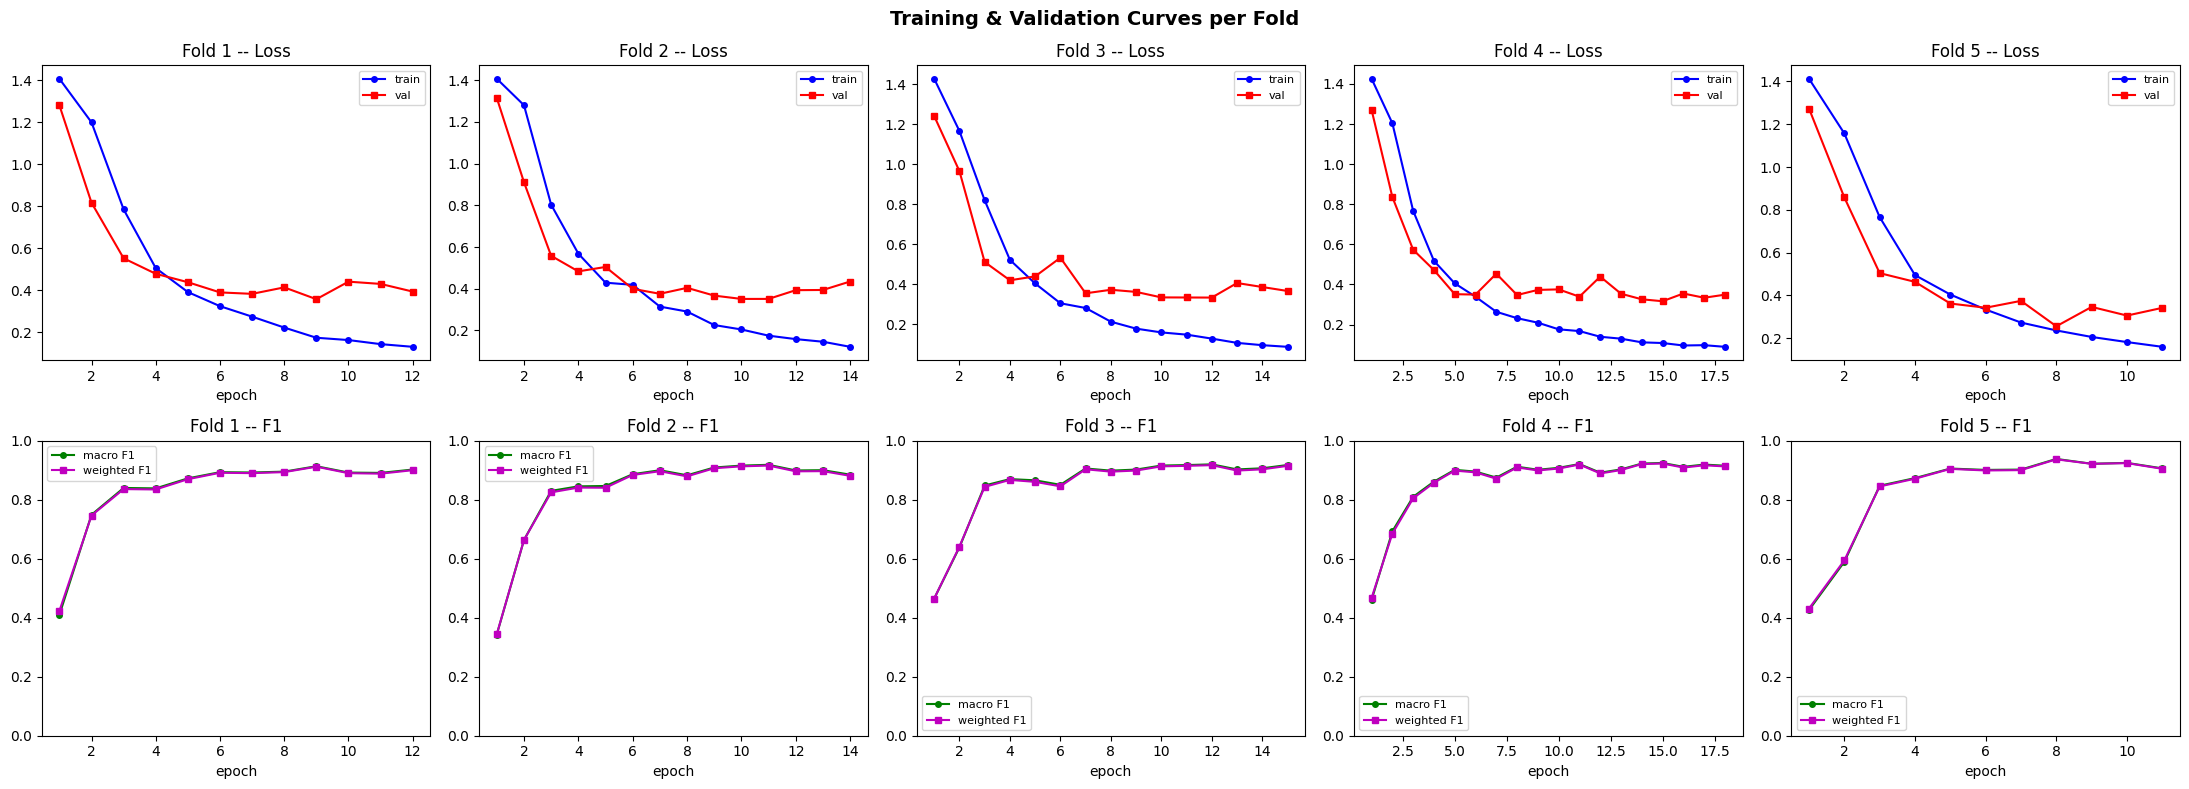

In [24]:
import matplotlib.pyplot as plt, matplotlib
matplotlib.rcParams["font.family"] = "DejaVu Sans"

hist = full_cv["history"]; nF = len(hist)
fig, axes = plt.subplots(2, nF, figsize=(4.4*nF, 8), squeeze=False)
fig.suptitle("Training & Validation Curves per Fold", fontsize=14, fontweight="bold")
for f, h in hist.items():
    ep = range(1, len(h["train_loss"])+1)
    axes[0][f].plot(ep, h["train_loss"], "b-o", ms=4, label="train"); axes[0][f].plot(ep, h["val_loss"], "r-s", ms=4, label="val")
    axes[0][f].set_title(f"Fold {f+1} -- Loss"); axes[0][f].legend(fontsize=8); axes[0][f].set_xlabel("epoch")
    axes[1][f].plot(ep, h["macro_f1"], "g-o", ms=4, label="macro F1"); axes[1][f].plot(ep, h["weighted_f1"], "m-s", ms=4, label="weighted F1")
    axes[1][f].set_title(f"Fold {f+1} -- F1"); axes[1][f].set_ylim(0, 1); axes[1][f].legend(fontsize=8); axes[1][f].set_xlabel("epoch")
plt.tight_layout(); plt.savefig("training_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## Section 14 -- Ensemble Hold-out Evaluation (`Test_Data.xlsx`, 500 rows, unseen)

Predictions on the official test set average the softmax probabilities of all 5 fold models, then take `argmax` -- there is no per-class threshold to calibrate with a single 4-way head. A single **stable** `EmojiIntentEncoder`, fit on the **entire train pool** (never on test labels), supplies intent features for every fold model at inference.

In [25]:
stable_encoder = EmojiIntentEncoder().fit(df_train.text.values, df_train.class_id.values)
print(f"Stable encoder fit on {len(df_train)} train rows (no test leakage).")

def ensemble_predict(models, encoder, raw_texts, max_len=None, batch_size=32, preprocess_fn=None):
    """Mean softmax probability (N, N_CLASSES) across fold models using ONE shared, stable encoder."""
    max_len = CFG["MAX_LEN"] if max_len is None else max_len
    pp = preprocess if preprocess_fn is None else preprocess_fn
    exp = [pp(t) for t in raw_texts]
    feats = torch.tensor(encoder.transform(raw_texts), dtype=torch.float32)
    prob_sum = np.zeros((len(raw_texts), N_CLASSES))
    for m in models:
        m.to(DEVICE).eval()
        for i in range(0, len(raw_texts), batch_size):
            chunk = exp[i:i+batch_size]
            t = tokenizer(chunk, max_length=max_len, padding="max_length", truncation=True, return_tensors="pt")
            with torch.no_grad():
                logits = m(t["input_ids"].to(DEVICE), t["attention_mask"].to(DEVICE), feats[i:i+batch_size].to(DEVICE))
            prob_sum[i:i+batch_size] += F.softmax(logits, dim=1).cpu().numpy()
        m.to("cpu")
    return prob_sum / len(models)

test_prob = ensemble_predict(full_cv["models"], stable_encoder, df_test.text.values)
test_pred = test_prob.argmax(axis=1)
test_true = df_test.class_id.values

print("="*70); print("HOLD-OUT TEST -- 5-FOLD ENSEMBLE (unseen data)"); print("="*70)
print(classification_report(test_true, test_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

print(f"Accuracy         : {accuracy_score(test_true, test_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(test_true, test_pred):.4f}")
print(f"Macro F1         : {f1_score(test_true, test_pred, average='macro', zero_division=0):.4f}")
print(f"Weighted F1      : {f1_score(test_true, test_pred, average='weighted', zero_division=0):.4f}")
print(f"MCC              : {matthews_corrcoef(test_true, test_pred):.4f}")
try:
    auc_ovr = roc_auc_score(test_true, test_prob, multi_class="ovr", average="macro")
    print(f"AUC (OvR, macro) : {auc_ovr:.4f}")
except ValueError as e:
    print(f"AUC (OvR) unavailable: {e}")

Stable encoder fit on 2548 train rows (no test leakage).
HOLD-OUT TEST -- 5-FOLD ENSEMBLE (unseen data)
                   precision    recall  f1-score   support

   pure_sarcastic     0.7089    0.8235    0.7619       136
   pure_offensive     0.7890    0.6615    0.7197       130
sarcastic_offense     0.5250    0.4922    0.5081       128
          neutral     0.9115    0.9717    0.9406       106

         accuracy                         0.7280       500
        macro avg     0.7336    0.7372    0.7326       500
     weighted avg     0.7256    0.7280    0.7238       500

Accuracy         : 0.7280
Balanced Accuracy: 0.7372
Macro F1         : 0.7326
Weighted F1      : 0.7238
MCC              : 0.6381
AUC (OvR, macro) : 0.9144


### Confusion matrix & per-class ROC curves (hold-out test)

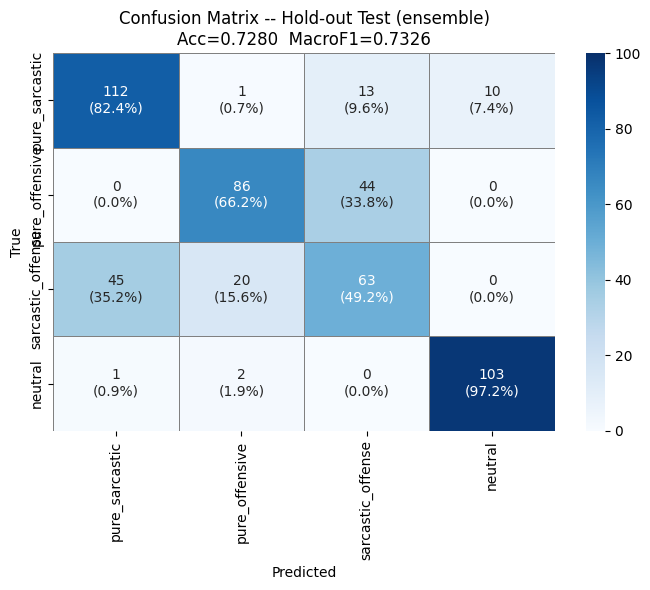

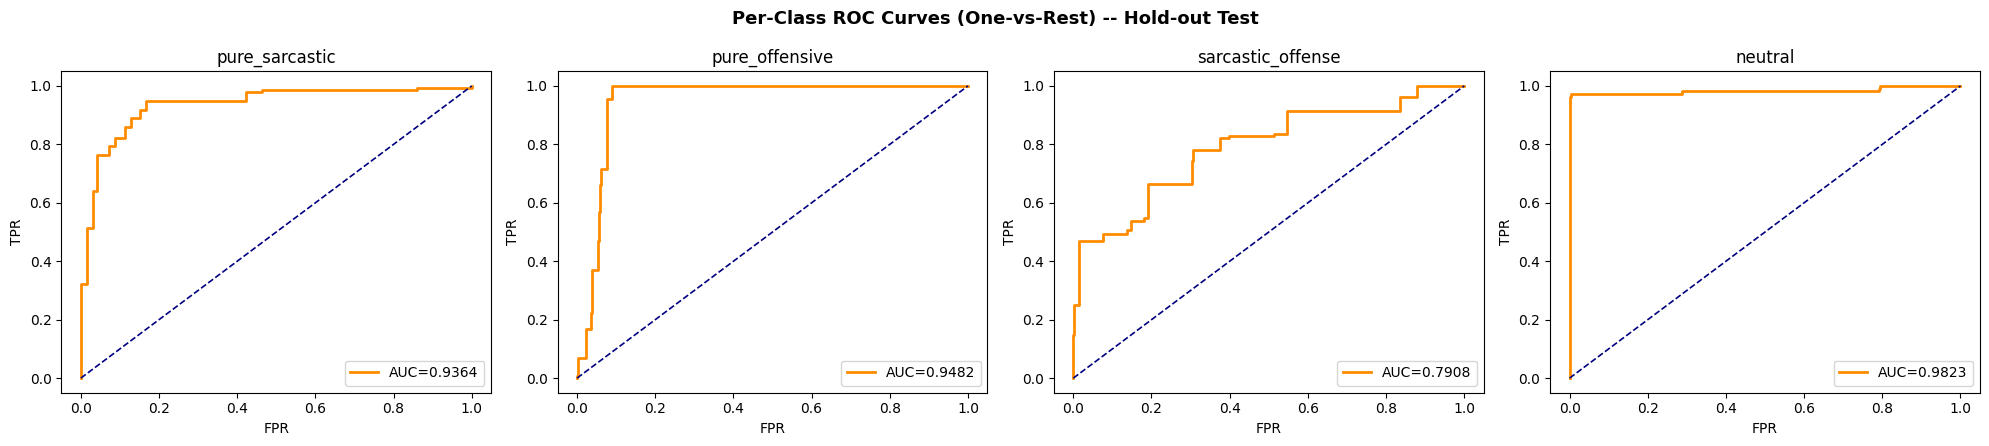

In [26]:
import seaborn as sns

cm = confusion_matrix(test_true, test_pred, labels=range(N_CLASSES))
pct = cm / cm.sum(axis=1, keepdims=True) * 100
annot = np.array([[f"{cm[i,j]}\n({pct[i,j]:.1f}%)" for j in range(N_CLASSES)] for i in range(N_CLASSES)])
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            ax=ax, vmin=0, vmax=100, linewidths=.5, linecolor="gray", annot_kws={"size": 10})
ax.set_title(f"Confusion Matrix -- Hold-out Test (ensemble)\nAcc={accuracy_score(test_true,test_pred):.4f}  MacroF1={f1_score(test_true,test_pred,average='macro',zero_division=0):.4f}")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, N_CLASSES, figsize=(5*N_CLASSES, 4.5))
fig.suptitle("Per-Class ROC Curves (One-vs-Rest) -- Hold-out Test", fontsize=13, fontweight="bold")
for c in range(N_CLASSES):
    yt_bin = (test_true == c).astype(int)
    fpr, tpr, _ = roc_curve(yt_bin, test_prob[:, c])
    axes[c].plot(fpr, tpr, "darkorange", lw=2, label=f"AUC={auc(fpr,tpr):.4f}")
    axes[c].plot([0, 1], [0, 1], "navy", ls="--", lw=1.2)
    axes[c].set_title(CLASS_NAMES[c]); axes[c].legend(loc="lower right")
    axes[c].set_xlabel("FPR"); axes[c].set_ylabel("TPR")
plt.tight_layout(); plt.savefig("roc_curves_ovr.png", dpi=150, bbox_inches="tight"); plt.show()

## Section 15 -- Per-Class Emoji vs Word Contribution (LIME, Hold-out Test, Preprocessed Text)

**Text form:** LIME explains the **preprocessed** (emoji-expanded) string -- the exact input the model consumes -- not raw text, so attributions are faithful to the deployed pipeline. Bracketed emoji phrases (e.g. `[ব্যঙ্গাত্মক হাসি]`) are kept atomic via a NUL-joined surrogate encoding.

**Split:** LIME is run on the **hold-out test set** (never on train), because the test set is the only fully independent sample -- fitting or explaining on train risks reflecting fold-specific encoder statistics rather than genuine generalizable behaviour.

**Per-class design:** up to `CFG["LIME_PER_CLASS_N"]` emoji-bearing test rows are sampled **per true class**; each is explained for its own predicted-class probability, LIME features are split into emoji tokens vs. word tokens, and the mean `|weight|` of each group is aggregated per class. A paired one-sided test (t-test + Wilcoxon) checks H1: emoji weight > word weight, separately for every class.

In [27]:
from lime.lime_text import LimeTextExplainer
from contextlib import contextmanager

def _units(exp_text):
    """Split preprocessed text into units; bracketed emoji phrases stay atomic."""
    toks, units, buf = exp_text.split(" "), [], []
    for t in toks:
        if buf:
            buf.append(t)
            if t.endswith("]"): units.append(" ".join(buf)); buf = []
        elif t.startswith("[") and not t.endswith("]"):
            buf = [t]
        else:
            units.append(t)
    if buf: units.append(" ".join(buf))
    return [u for u in units if u]

def to_surrogate(exp_text):
    return " ".join(u.replace(" ", "\x00") for u in _units(exp_text))

def is_emoji_token(tok):
    return tok.strip().startswith("[")

@contextmanager
def lime_models_resident(models):
    """Keep fold models on DEVICE for a whole batch of explanations (avoids per-call host<->device transfer)."""
    try:
        for m in models: m.to(DEVICE).eval()
        yield models
    finally:
        for m in models: m.to("cpu")
        if torch.cuda.is_available(): torch.cuda.empty_cache()

def make_lime_predict_fn_pre(models, intent_vec, target_class):
    """LIME predict_fn over surrogate (preprocessed) strings; intent vector held FIXED;
    returns 2-col [1-p_c, p_c] so LIME explains P(target_class)."""
    feat0 = torch.tensor(np.asarray(intent_vec, dtype=np.float32))
    bs = CFG["LIME_INFER_BATCH"]
    use_amp = bool(CFG["LIME_AUTOCAST"]) and torch.cuda.is_available()

    def predict_fn(surrogate_texts):
        real = [s.replace("\x00", " ") for s in surrogate_texts]
        prob = np.zeros(len(real), dtype=np.float64)
        for i in range(0, len(real), bs):
            chunk = real[i:i+bs]
            enc = tokenizer(chunk, max_length=CFG["MAX_LEN"], padding=True, truncation=True, return_tensors="pt")
            ids, msk = enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE)
            feats = feat0.to(DEVICE).repeat(len(chunk), 1)
            acc = np.zeros(len(chunk), dtype=np.float64)
            for m in models:
                if next(m.parameters()).device != ids.device:
                    m.to(DEVICE)
                m.eval()
                with torch.inference_mode():
                    if use_amp:
                        with torch.autocast("cuda", dtype=torch.float16):
                            logits = m(ids, msk, feats)
                    else:
                        logits = m(ids, msk, feats)
                acc += F.softmax(logits.float(), dim=1)[:, target_class].cpu().numpy()
            prob[i:i+bs] = acc / len(models)
        return np.c_[1-prob, prob]
    return predict_fn

_LIME_SPLIT = r"\s+"

def _make_lime_text_explainer():
    return LimeTextExplainer(class_names=["other", "target"], split_expression=_LIME_SPLIT, bow=True)

def lime_explain_for_class(raw_text, target_class, models, num_samples=None, num_features=15):
    num_samples = CFG["LIME_SAMPLES"] if num_samples is None else num_samples
    exp_text  = preprocess(raw_text)
    surrogate = to_surrogate(exp_text)
    ivec      = stable_encoder.transform([raw_text])
    fn        = make_lime_predict_fn_pre(models, ivec, target_class)
    explainer = _make_lime_text_explainer()
    return explainer.explain_instance(surrogate, fn, num_features=num_features, num_samples=num_samples, labels=[1])

def lime_features(exp):
    return [(feat.replace("\x00", " "), w) for feat, w in exp.as_list(label=1)]

def emoji_word_split(feats):
    e = [abs(w) for f, w in feats if is_emoji_token(f)]
    w = [abs(wt) for f, wt in feats if not is_emoji_token(f)]
    return e, w

rng_lime = np.random.default_rng(SEED)
per_class_emoji, per_class_word = {c: [] for c in range(N_CLASSES)}, {c: [] for c in range(N_CLASSES)}

with lime_models_resident(full_cv["models"]):
    for c in range(N_CLASSES):
        idx_c = [i for i in range(len(df_test)) if test_true[i] == c and extract_emojis(df_test.text.iloc[i])]
        n_take = min(CFG["LIME_PER_CLASS_N"], len(idx_c))
        chosen = rng_lime.choice(idx_c, size=n_take, replace=False) if n_take > 0 else []
        print(f"Class {c} ({CLASS_NAMES[c]}): explaining {n_take}/{len(idx_c)} emoji-bearing test rows")
        for i in chosen:
            feats = lime_features(lime_explain_for_class(df_test.text.iloc[i], c, full_cv["models"]))
            e, w = emoji_word_split(feats)
            if e and w:                          # only genuine paired comparisons
                per_class_emoji[c].append(np.mean(e))
                per_class_word[c].append(np.mean(w))

Class 0 (pure_sarcastic): explaining 40/133 emoji-bearing test rows
Class 1 (pure_offensive): explaining 40/129 emoji-bearing test rows
Class 2 (sarcastic_offense): explaining 32/32 emoji-bearing test rows
Class 3 (neutral): explaining 6/6 emoji-bearing test rows


### Per-class emoji vs word contribution: table, statistics, and diagrams

=== Per-Class Emoji vs Word |LIME weight| (hold-out test) ===
            class  n_paired  emoji_mean  emoji_std  word_mean  word_std    diff  ttest_p  wilcoxon_p
   pure_sarcastic        40      0.1155     0.0622     0.0626    0.0231  0.0529   0.0000      0.0000
   pure_offensive        40      0.1983     0.1153     0.0947    0.0266  0.1036   0.0000      0.0000
sarcastic_offense        32      0.1049     0.1083     0.0893    0.0341  0.0156   0.2167      0.7673
          neutral         6      0.0399     0.0476     0.0506    0.0435 -0.0106   0.6512      0.6562


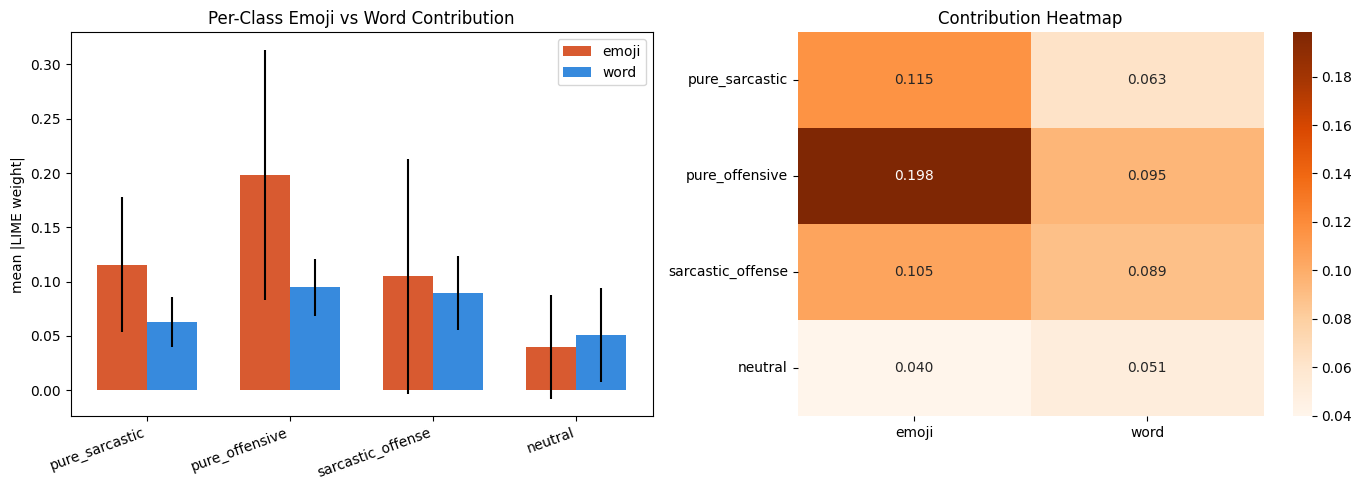

In [28]:
rows = []
for c in range(N_CLASSES):
    e_arr, w_arr = np.array(per_class_emoji[c]), np.array(per_class_word[c])
    if len(e_arr) >= 3:
        t_p = ttest_rel(e_arr, w_arr, alternative="greater").pvalue
        try:
            w_p = wilcoxon(e_arr, w_arr, alternative="greater").pvalue
        except ValueError:
            w_p = float("nan")
    else:
        t_p = w_p = float("nan")
    rows.append({"class": CLASS_NAMES[c], "n_paired": len(e_arr),
                 "emoji_mean": e_arr.mean() if len(e_arr) else np.nan, "emoji_std": e_arr.std() if len(e_arr) else np.nan,
                 "word_mean": w_arr.mean() if len(w_arr) else np.nan, "word_std": w_arr.std() if len(w_arr) else np.nan,
                 "diff": (e_arr.mean()-w_arr.mean()) if len(e_arr) and len(w_arr) else np.nan,
                 "ttest_p": t_p, "wilcoxon_p": w_p})
emoji_word_df = pd.DataFrame(rows)
print("=== Per-Class Emoji vs Word |LIME weight| (hold-out test) ===")
print(emoji_word_df.round(4).to_string(index=False))

x = np.arange(N_CLASSES); width = 0.35
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(x - width/2, emoji_word_df["emoji_mean"], width, yerr=emoji_word_df["emoji_std"], label="emoji", color="#D85A30")
axes[0].bar(x + width/2, emoji_word_df["word_mean"],  width, yerr=emoji_word_df["word_std"],  label="word",  color="#378ADD")
axes[0].set_xticks(x); axes[0].set_xticklabels(CLASS_NAMES, rotation=20, ha="right")
axes[0].set_ylabel("mean |LIME weight|"); axes[0].set_title("Per-Class Emoji vs Word Contribution"); axes[0].legend()

heat = emoji_word_df[["emoji_mean", "word_mean"]].to_numpy()
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Oranges", xticklabels=["emoji", "word"], yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title("Contribution Heatmap")
plt.tight_layout(); plt.savefig("emoji_vs_word_per_class.png", dpi=150, bbox_inches="tight"); plt.show()

## Section 16 -- Error Analysis

Per-class error rates, the dominant confusion for each class, concrete misclassified examples, and a confidence comparison between correct and incorrect ensemble predictions on the hold-out test set.

In [29]:
per_class_error_rows = []
for c in range(N_CLASSES):
    mask = test_true == c
    n_c = mask.sum()
    err_rate = 1.0 - (test_pred[mask] == c).mean() if n_c > 0 else float("nan")
    wrong_preds = test_pred[mask][test_pred[mask] != c]
    top_confusion = CLASS_NAMES[np.bincount(wrong_preds, minlength=N_CLASSES).argmax()] if len(wrong_preds) else "-"
    top_confusion_rate = (wrong_preds == np.bincount(wrong_preds, minlength=N_CLASSES).argmax()).mean() if len(wrong_preds) else 0.0
    per_class_error_rows.append({"class": CLASS_NAMES[c], "support": int(n_c), "error_rate": err_rate,
                                  "top_confusion": top_confusion, "top_confusion_rate": top_confusion_rate})
error_df = pd.DataFrame(per_class_error_rows)
print("=== Per-Class Error Rates & Dominant Confusions (hold-out test) ===")
print(error_df.round(4).to_string(index=False))

=== Per-Class Error Rates & Dominant Confusions (hold-out test) ===
            class  support  error_rate     top_confusion  top_confusion_rate
   pure_sarcastic      136      0.1765 sarcastic_offense              0.5417
   pure_offensive      130      0.3385 sarcastic_offense              1.0000
sarcastic_offense      128      0.5078    pure_sarcastic              0.6923
          neutral      106      0.0283    pure_offensive              0.6667


=== Hardest Misclassified Examples (top-2 per class by prediction confidence) ===

-- True class: pure_sarcastic --
  text      : বাহবা দিতে হয়, এই বউ নিজে মিথ্যা বলে সততার লেকচার দিলো, নির্বোধ সাহস আছে বলতে হবে।
  predicted : sarcastic_offense (prob=0.918)
  text      : Wah ki bhalo captain, toss জিতে ম্যাচ হারায়! 🏏🤡
  predicted : sarcastic_offense (prob=0.912)

-- True class: pure_offensive --
  text      : Chor company, সেবা দেয় না টাকা খায়। 💩
  predicted : sarcastic_offense (prob=0.659)
  text      : Chor company, সেবা দেয় না টাকা খায়। 💩
  predicted : sarcastic_offense (prob=0.659)

-- True class: sarcastic_offense --
  text      : Faltu political propaganda, মানুষকে বিপথে পরিচালিত করার নোংরা চেষ্টা!
  predicted : pure_offensive (prob=0.923)
  text      : Faltu political propaganda, মানুষকে বিপথে পরিচালিত করার নোংরা চেষ্টা!
  predicted : pure_offensive (prob=0.923)

-- True class: neutral --
  text      : Ajker news niye comment ta ekdom baje, amar mote valo hoy nai. 🚫
  pred

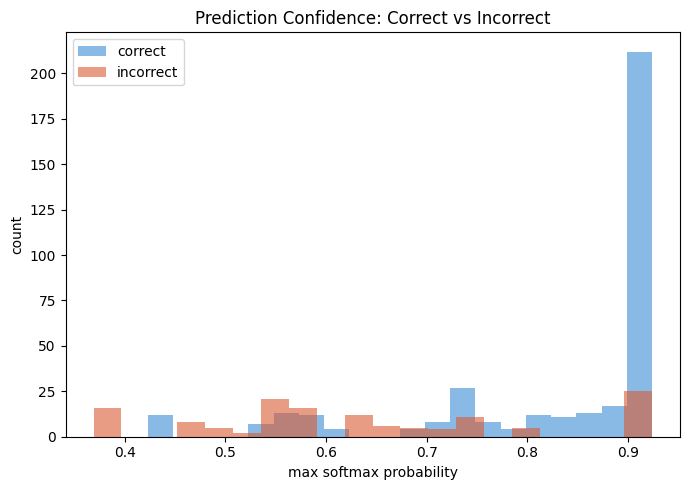

In [30]:
print("=== Hardest Misclassified Examples (top-2 per class by prediction confidence) ===")
wrong_mask = test_pred != test_true
for c in range(N_CLASSES):
    idx_c = np.where(wrong_mask & (test_true == c))[0]
    if len(idx_c) == 0:
        print(f"\n{CLASS_NAMES[c]}: no misclassifications."); continue
    conf = test_prob[idx_c, test_pred[idx_c]]
    top = idx_c[np.argsort(-conf)[:2]]
    print(f"\n-- True class: {CLASS_NAMES[c]} --")
    for i in top:
        print(f"  text      : {df_test.text.iloc[i]}")
        print(f"  predicted : {CLASS_NAMES[test_pred[i]]} (prob={test_prob[i, test_pred[i]]:.3f})")

print("\n=== Confidence: Correct vs Incorrect Predictions ===")
max_prob = test_prob.max(axis=1)
correct_conf, wrong_conf = max_prob[~wrong_mask], max_prob[wrong_mask]
print(f"  Mean max-softmax   | correct: {correct_conf.mean():.4f}  incorrect: {wrong_conf.mean():.4f}")
print(f"  Median max-softmax | correct: {np.median(correct_conf):.4f}  incorrect: {np.median(wrong_conf):.4f}")
print(f"  % predictions with max-prob > 0.9 | correct: {(correct_conf>0.9).mean()*100:.1f}%  incorrect: {(wrong_conf>0.9).mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(correct_conf, bins=20, alpha=0.6, label="correct", color="#3B8BD4")
ax.hist(wrong_conf, bins=20, alpha=0.6, label="incorrect", color="#D85A30")
ax.set_xlabel("max softmax probability"); ax.set_ylabel("count"); ax.set_title("Prediction Confidence: Correct vs Incorrect")
ax.legend(); plt.tight_layout(); plt.savefig("confidence_correct_vs_incorrect.png", dpi=150, bbox_inches="tight"); plt.show()

## Section 17 -- Ablation Study

Each ablation reuses `run_cv()` with identical hyperparameters, epochs and CV splits as the main model: (a) **No-Emoji** disables emoji expansion (`preprocess_noemoji`), and (b) **No-Augmentation** disables the emoji-cluster substitution. Both are evaluated with the same ensemble procedure on the held-out test set.

In [ ]:
ABLATIONS = {
    "No-Emoji":        dict(preprocess_fn=preprocess_noemoji, augment=True),
    "No-Augmentation": dict(preprocess_fn=None, augment=False),
}

def evaluate_on_test(cv_result, preprocess_fn=None):
    """Ensemble-evaluate a run_cv() result on df_test; returns (macro_f1, weighted_f1, accuracy)."""
    enc = EmojiIntentEncoder().fit(df_train.text.values, df_train.class_id.values)
    prob = ensemble_predict(cv_result["models"], enc, df_test.text.values, preprocess_fn=preprocess_fn)
    pred = prob.argmax(axis=1)
    return (f1_score(test_true, pred, average="macro", zero_division=0),
            f1_score(test_true, pred, average="weighted", zero_division=0),
            accuracy_score(test_true, pred))

main_scores = (f1_score(test_true, test_pred, average="macro", zero_division=0),
               f1_score(test_true, test_pred, average="weighted", zero_division=0),
               accuracy_score(test_true, test_pred))
results = {"Full Model (EmoClassifier4)": main_scores}

for name, kw in ABLATIONS.items():
    print(f"\n--- Running ablation: {name} ---")
    seed_everything()
    cv_res = run_cv(df_train, strat_key_train.values, BEST_HP, tag=name, verbose=False, **kw)
    results[name] = evaluate_on_test(cv_res, preprocess_fn=kw.get("preprocess_fn"))
    del cv_res
    if torch.cuda.is_available(): torch.cuda.empty_cache()

print("\n" + "="*60); print("ABLATION SUMMARY -- Hold-out Test"); print("="*60)
abl_df = pd.DataFrame(results, index=["macro_f1", "weighted_f1", "accuracy"]).T
print(abl_df.round(4).to_string())


--- Running ablation: No-Emoji ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


--- Running ablation: No-Augmentation ---


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

## Section 18 -- Statistical Significance (Bootstrap 95% CIs)

In [ ]:
def macro_f1_metric(yt, yp): return f1_score(yt, yp, average="macro", zero_division=0)
def weighted_f1_metric(yt, yp): return f1_score(yt, yp, average="weighted", zero_division=0)

print("="*70); print(f"STATISTICAL SIGNIFICANCE (Bootstrap {CFG['BOOTSTRAP_N']}x resample, 95% CI)"); print("="*70)
mean_mf1, lo_mf1, hi_mf1 = bootstrap_ci(test_true, test_pred, macro_f1_metric)
mean_wf1, lo_wf1, hi_wf1 = bootstrap_ci(test_true, test_pred, weighted_f1_metric)
print(f"Macro F1   : {mean_mf1:.4f}  [95% CI {lo_mf1:.4f}, {hi_mf1:.4f}]")
print(f"Weighted F1: {mean_wf1:.4f}  [95% CI {lo_wf1:.4f}, {hi_wf1:.4f}]")

print("\nPer-class F1 with bootstrap CI:")
for c in range(N_CLASSES):
    def f1_c(yt, yp, c=c): return f1_score(yt == c, yp == c, zero_division=0)
    m, lo, hi = bootstrap_ci(test_true, test_pred, f1_c)
    print(f"  {CLASS_NAMES[c]:<18}: {m:.4f}  [95% CI {lo:.4f}, {hi:.4f}]")